In [2]:
%pylab inline
import os
import numpy as np
import astropy.io.fits as pyfits
import astropy.table as astTable
import sim_analysis_utilities as utilities
import healpy as hp

Populating the interactive namespace from numpy and matplotlib


# S19A PSF (new star mask) not in new FD cut
The new FDFC cut with f-delta$<0.01$ cut

In [9]:
def get_FDFC_flag(ra,dec,version='s19',degree=True):
    # Read fdfc file
    if version=='s16':
        hpfname =   "s16a_wide2_fdfc.fits"
    elif version=='s18':
        hpfname =   "s18a_fdfc_hp_contarea.fits"
    elif version=='s19':
        hpfname =   "s19a_fdfc_hp_contarea_izy-gt-5_trimmed_fd001.fits"
    else:
        return np.ones(len(ra),dtype=bool)
    hpfname =   os.path.join('/work/xiangchong.li/work/galSim-HSC/database',hpfname)
    m       =   hp.read_map(hpfname, nest = True, dtype = np.bool)

    # Get flag
    if degree:
        mfactor =   np.pi/180.
    else:
        mfactor =   1.
    indices_map =   np.where(m)[0]
    nside   =   hp.get_nside(m)
    phi     =   ra*mfactor
    theta   =   np.pi/2. - dec*mfactor
    indices_obj = hp.ang2pix(nside, theta, phi, nest = True)
    return np.in1d(indices_obj, indices_map)

def get_mask_visit_104994(ra,dec):
    def _calDistanceAngle(a1, d1):
        a2=130.43
        d2=-1.02
        a1_f64 = np.array(a1, dtype = np.float64)*np.pi/180.
        d1_f64 = np.array(d1, dtype = np.float64)*np.pi/180.
        a2_f64 = np.array(a2, dtype = np.float64)*np.pi/180.
        d2_f64 = np.array(d2, dtype = np.float64)*np.pi/180.
        return np.arccos(np.cos(d1_f64)*np.cos(d2_f64)*np.cos(a1_f64-a2_f64)+np.sin(d1_f64)*np.sin(d2_f64))/np.pi*180.
    d=_calDistanceAngle(ra,dec)
    mask=(ra>130.5)&(ra<131.5)&(dec<-1.5)
    return (d>0.80)&(~mask)

In [16]:
psfs1=astTable.Table.read('wrkDir/s19/s19-1/info_newS19Mask_sim.csv')
raP=psfs1['psf_ra']
decP=psfs1['psf_dec']
maskP0=get_FDFC_flag(raP,decP,'s19')
maskP0=(maskP0&get_mask_visit_104994(raP,decP))
print(np.sum(~maskP0))
psfs2=psfs1[maskP0]
psfs2.write('wrkDir/s19/s19-1/info_newS19Mask_fd001_sim.csv',overwrite=True)
nAll=0.
nMasked=0.

NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
49


816582
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT


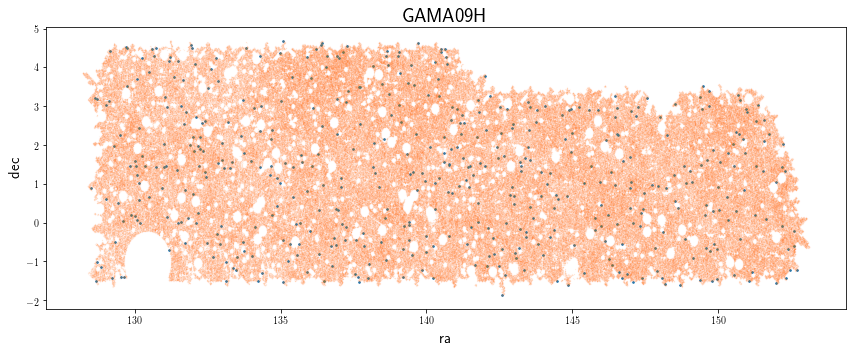

In [17]:
fieldname='GAMA09H'
cat=pyfits.getdata('wrkDir/s19/s19-1/anaCat_newS19Mask/catalog_obs_reGaus_no_m/%s_no_m.fits' %fieldname)[0::10]
raG=cat['i_ra']
decG=cat['i_dec']
print(len(raG))
nAll+=len(raG)
maskG=get_FDFC_flag(raG,decG)
maskP=(psfs1['field']==fieldname)
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fieldname,fontsize=20)
plt.scatter(raP[maskP0&maskP],decP[maskP0&maskP],s=2.5)
plt.scatter(raG[maskG],decG[maskG],s=0.01,alpha=0.2)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

19176
21


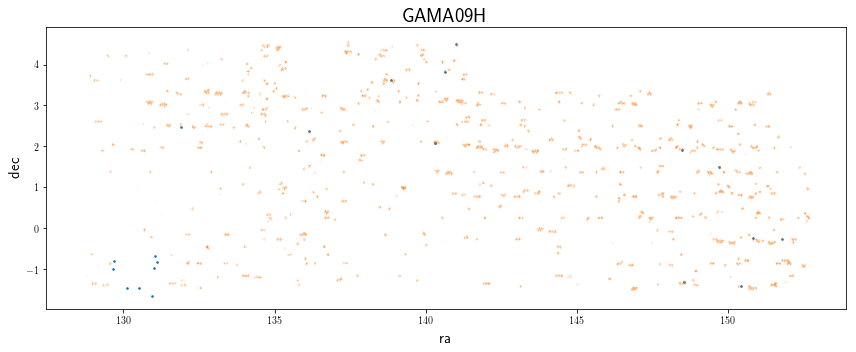

In [18]:
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fieldname,fontsize=20)
plt.scatter(raP[(~maskP0)&maskP],decP[(~maskP0)&maskP],s=2.5)
plt.scatter(raG[~maskG],decG[~maskG],s=0.1,alpha=0.1)
print(len(raG[~maskG]))
nMasked+=len(raG[~maskG])
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()
print(len(raP[(~maskP0)&maskP]))

355484
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT


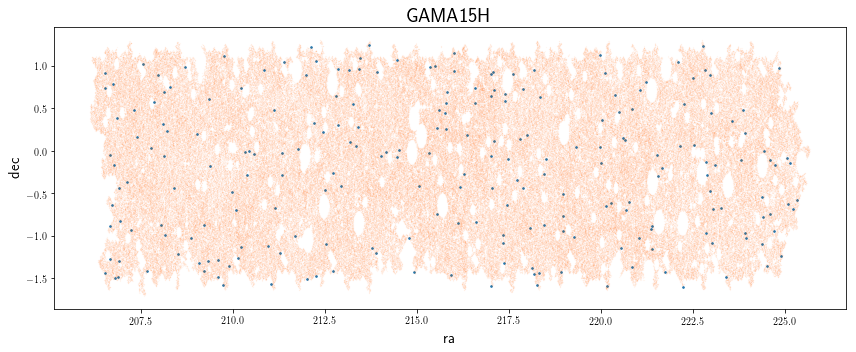

In [6]:
fieldname='GAMA15H'
cat=pyfits.getdata('wrkDir/s19/s19-1/anaCat_newS19Mask/catalog_obs_reGaus_no_m/%s_no_m.fits' %fieldname)[0::10]
raG=cat['i_ra']
decG=cat['i_dec']
print(len(raG))
nAll+=len(raG)
maskG=get_FDFC_flag(raG,decG)
maskP=(psfs1['field']==fieldname)
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fieldname,fontsize=20)
plt.scatter(raP[maskP0&maskP],decP[maskP0&maskP],s=2.5)
plt.scatter(raG[maskG],decG[maskG],s=0.01,alpha=0.2)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

3051
0


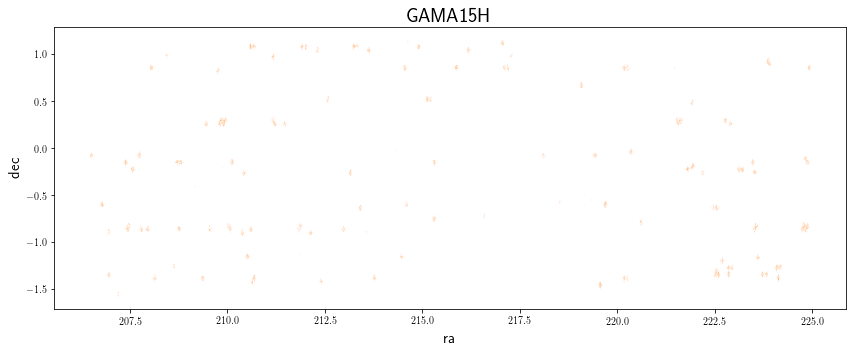

In [7]:
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fieldname,fontsize=20)
plt.scatter(raP[(~maskP0)&maskP],decP[(~maskP0)&maskP],s=2.5)
plt.scatter(raG[~maskG],decG[~maskG],s=0.1,alpha=0.1)
print(len(raG[~maskG]))
nMasked+=len(raG[~maskG])
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()
print(len(raP[(~maskP0)&maskP]))

1035168
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT


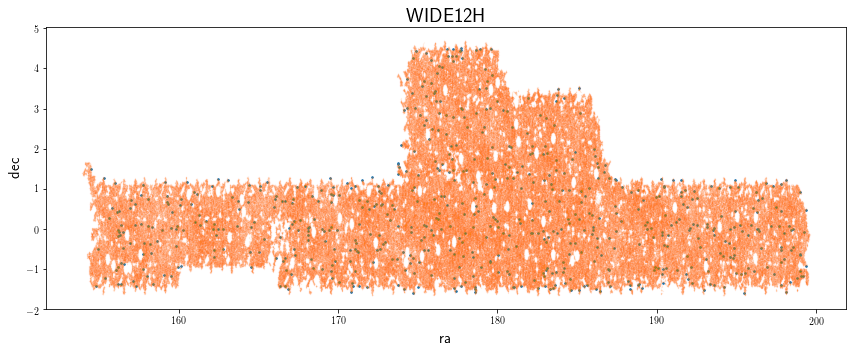

In [8]:
fieldname='WIDE12H'
cat=pyfits.getdata('wrkDir/s19/s19-1/anaCat_newS19Mask/catalog_obs_reGaus_no_m/%s_no_m.fits' %fieldname)[0::10]
raG=cat['i_ra']
decG=cat['i_dec']
print(len(raG))
nAll+=len(raG)
maskG=get_FDFC_flag(raG,decG)
maskP=(psfs1['field']==fieldname)
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fieldname,fontsize=20)
plt.scatter(raP[maskP0&maskP],decP[maskP0&maskP],s=2.5)
plt.scatter(raG[maskG],decG[maskG],s=0.01,alpha=0.2)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

35043
20


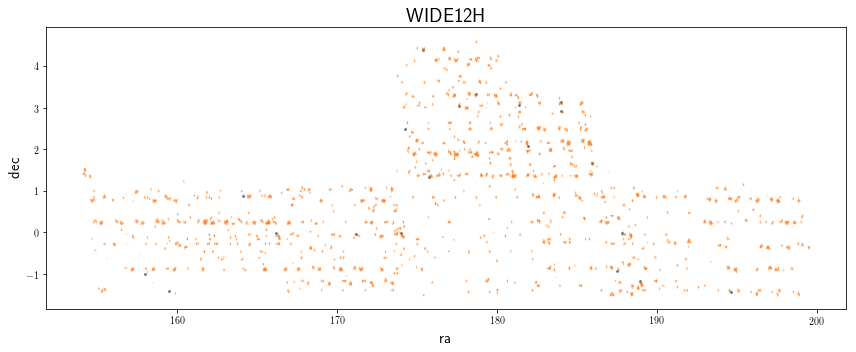

In [9]:
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fieldname,fontsize=20)
plt.scatter(raP[(~maskP0)&maskP],decP[(~maskP0)&maskP],s=2.5)
plt.scatter(raG[~maskG],decG[~maskG],s=0.1,alpha=0.1)
print(len(raG[~maskG]))
nMasked+=len(raG[~maskG])
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()
print(len(raP[(~maskP0)&maskP]))

262337
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT


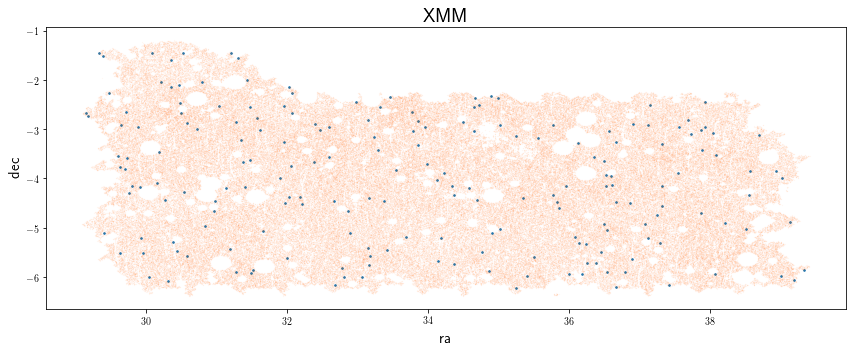

In [10]:
fieldname='XMM'
cat=pyfits.getdata('wrkDir/s19/s19-1/anaCat_newS19Mask/catalog_obs_reGaus_no_m/%s_no_m.fits' %fieldname)[0::10]
raG=cat['i_ra']
decG=cat['i_dec']
print(len(raG))
nAll+=len(raG)
maskG=get_FDFC_flag(raG,decG)
maskP=(psfs1['field']==fieldname)
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fieldname,fontsize=20)
plt.scatter(raP[maskP0&maskP],decP[maskP0&maskP],s=2.5)
plt.scatter(raG[maskG],decG[maskG],s=0.01,alpha=0.2)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

2957
2


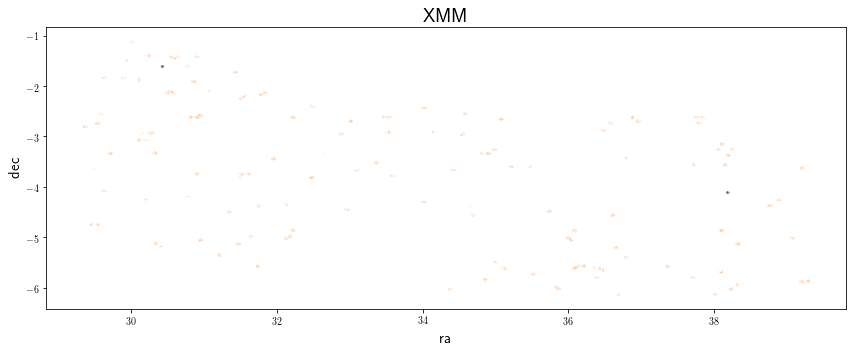

In [11]:
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fieldname,fontsize=20)
plt.scatter(raP[(~maskP0)&maskP],decP[(~maskP0)&maskP],s=2.5)
plt.scatter(raG[~maskG],decG[~maskG],s=0.1,alpha=0.1)
print(len(raG[~maskG]))
nMasked+=len(raG[~maskG])
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()
print(len(raP[(~maskP0)&maskP]))

375226
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT


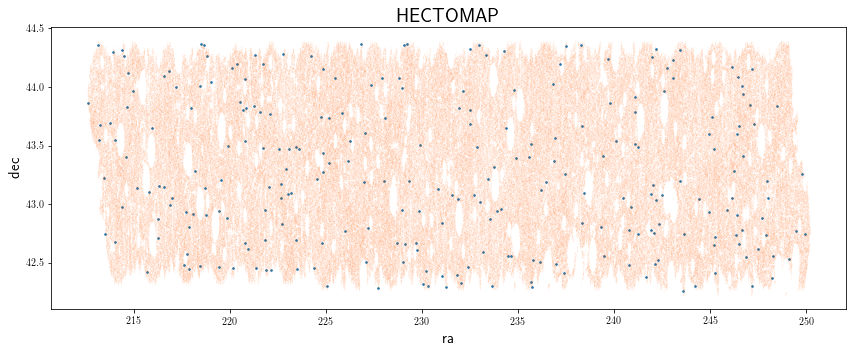

In [12]:
fieldname='HECTOMAP'
cat=pyfits.getdata('wrkDir/s19/s19-1/anaCat_newS19Mask/catalog_obs_reGaus_no_m/%s_no_m.fits' %fieldname)[0::10]
raG=cat['i_ra']
decG=cat['i_dec']
print(len(raG))
nAll+=len(raG)
maskG=get_FDFC_flag(raG,decG)
maskP=(psfs1['field']==fieldname)
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fieldname,fontsize=20)
plt.scatter(raP[maskP0&maskP],decP[maskP0&maskP],s=2.5)
plt.scatter(raG[maskG],decG[maskG],s=0.01,alpha=0.2)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

4835
2


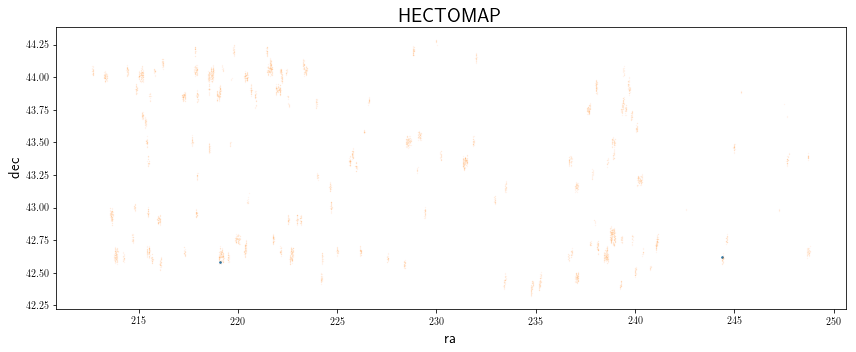

In [13]:
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fieldname,fontsize=20)
plt.scatter(raP[(~maskP0)&maskP],decP[(~maskP0)&maskP],s=2.5)
plt.scatter(raG[~maskG],decG[~maskG],s=0.1,alpha=0.1)
print(len(raG[~maskG]))
nMasked+=len(raG[~maskG])
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()
print(len(raP[(~maskP0)&maskP]))

815663
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT


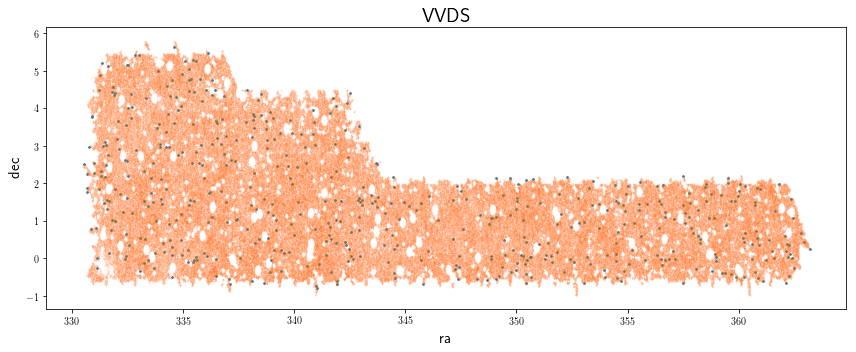

In [14]:
fieldname='VVDS'
cat=pyfits.getdata('wrkDir/s19/s19-1/anaCat_newS19Mask/catalog_obs_reGaus_no_m/%s_no_m.fits' %fieldname)[0::10]
raG=cat['i_ra']
decG=cat['i_dec']
print(len(raG))
nAll+=len(raG)
maskG=get_FDFC_flag(raG,decG)
maskP=(psfs1['field']==fieldname)
addG=(raG<300.).astype(int)*360
addP=(raP<300.).astype(int)*360
raG=raG+addG
raP=raP+addP
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fieldname,fontsize=20)
plt.scatter(raP[maskP0&maskP],decP[maskP0&maskP],s=2.5)
plt.scatter(raG[maskG],decG[maskG],s=0.01,alpha=0.2)
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()

15039
4


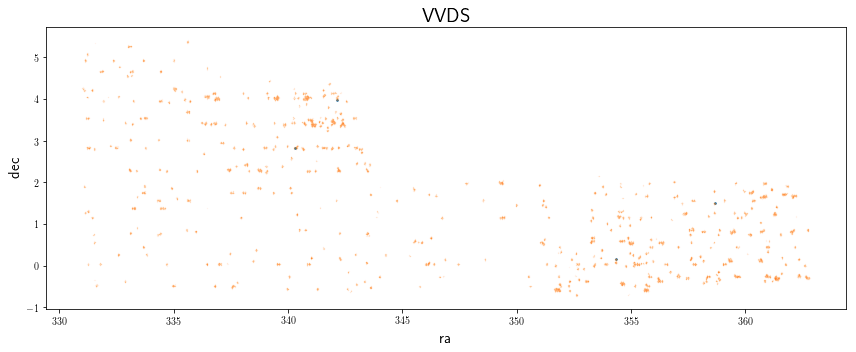

In [15]:
fig=plt.figure(figsize=(12,5))
plt.title('%s' %fieldname,fontsize=20)
plt.scatter(raP[(~maskP0)&maskP],decP[(~maskP0)&maskP],s=2.5)
plt.scatter(raG[~maskG],decG[~maskG],s=0.1,alpha=0.1)
print(len(raG[~maskG]))
nMasked+=len(raG[~maskG])
plt.xlabel('ra',fontsize=15)
plt.ylabel('dec',fontsize=15)
plt.tight_layout()
print(len(raP[(~maskP0)&maskP]))

In [16]:
print(nAll,nMasked)
print(nMasked/nAll)

3660460.0 80101.0
0.021882768832332547


In [5]:
nAll2=0.
nMasked2=0.
for fn in utilities.field_names.keys():
    cat=pyfits.getdata('wrkDir/s19/s19-1/anaCat_newS19Mask/catalog_obs_reGaus_no_m/%s_no_m.fits' %fn)
    maskG=get_FDFC_flag(cat['i_ra'],cat['i_dec'])
    print(1-np.sum(maskG)/len(maskG))
    nAll2+=len(maskG)
    nMasked2+=np.sum(~maskG)
    pyfits.writeto('wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/catalog_obs_reGaus_no_m/%s_no_m.fits' %fn,cat[maskG],overwrite=True)

NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
0.011166591254501368
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
0.02357056897783305
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
0.03365840459310998
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
0.008416712801055048
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
0.01853143235170218
NSIDE = 1024
ORDERING = NESTED in fits file
INDXSCHM = IMPLICIT
0.012746212141402036


In [6]:
print(nAll2,nMasked2)
print(nMasked2/nAll2)

36604571.0 799089.0
0.02183030638441303
